In [1]:
# 1. Import Pandas
import pandas as pd

# 2. Import NumPy
import numpy as np

# 3. Import Matplotlib
import matplotlib.pyplot as plt

# 4. Import Seaborn
import seaborn as sns

# 5. Import Scikit-learn
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors

# Display settings
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
# Load Fashion Dataset
df = pd.read_csv(
    r"C:\Users\swapn\OneDrive\Desktop\fashan\styles.csv",
    on_bad_lines="skip"
)

# Display first 5 rows
df.head()

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


In [7]:
print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset loaded successfully!
Shape: (44424, 10)
Columns: ['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName']


In [8]:
df.shape

(44424, 10)

In [9]:
df.columns

Index(['id', 'gender', 'masterCategory', 'subCategory', 'articleType',
       'baseColour', 'season', 'year', 'usage', 'productDisplayName'],
      dtype='object')

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44424 entries, 0 to 44423
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  44424 non-null  int64  
 1   gender              44424 non-null  object 
 2   masterCategory      44424 non-null  object 
 3   subCategory         44424 non-null  object 
 4   articleType         44424 non-null  object 
 5   baseColour          44409 non-null  object 
 6   season              44403 non-null  object 
 7   year                44423 non-null  float64
 8   usage               44107 non-null  object 
 9   productDisplayName  44417 non-null  object 
dtypes: float64(1), int64(1), object(8)
memory usage: 3.4+ MB


In [11]:
df.head(10)

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt
5,1855,Men,Apparel,Topwear,Tshirts,Grey,Summer,2011.0,Casual,Inkfruit Mens Chain Reaction T-shirt
6,30805,Men,Apparel,Topwear,Shirts,Green,Summer,2012.0,Ethnic,Fabindia Men Striped Green Shirt
7,26960,Women,Apparel,Topwear,Shirts,Purple,Summer,2012.0,Casual,Jealous 21 Women Purple Shirt
8,29114,Men,Accessories,Socks,Socks,Navy Blue,Summer,2012.0,Casual,Puma Men Pack of 3 Socks
9,30039,Men,Accessories,Watches,Watches,Black,Winter,2016.0,Casual,Skagen Men Black Watch


In [12]:
df.describe(include="all")

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
count,44424.000000,44424,44424,44424,44424,44409,44403,44423.000000,44107,44417
unique,NaN,5,7,45,143,46,4,NaN,8,31121
top,NaN,Men,Apparel,Topwear,Tshirts,Black,Summer,NaN,Casual,Lucera Women Silver Earrings
freq,NaN,22147,21397,15402,7067,9728,21472,NaN,34406,82
mean,29696.334301,NaN,NaN,NaN,NaN,NaN,NaN,2012.806497,NaN,NaN
std,17049.490518,NaN,NaN,NaN,NaN,NaN,NaN,2.126480,NaN,NaN
min,1163.000000,NaN,NaN,NaN,NaN,NaN,NaN,2007.000000,NaN,NaN
25%,14768.750000,NaN,NaN,NaN,NaN,NaN,NaN,2011.000000,NaN,NaN
50%,28618.500000,NaN,NaN,NaN,NaN,NaN,NaN,2012.000000,NaN,NaN
75%,44683.250000,NaN,NaN,NaN,NaN,NaN,NaN,2015.000000,NaN,NaN


In [13]:
df.isnull().sum()

id                      0
gender                  0
masterCategory          0
subCategory             0
articleType             0
baseColour             15
season                 21
year                    1
usage                 317
productDisplayName      7
dtype: int64

##**Data Cleaning**

In [14]:
# 1. Check missing values
print("Missing Values:")
print(df.isnull().sum())

# 2. Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# 3. Remove duplicate records
df = df.drop_duplicates()

# 4. Remove extra spaces from column names
df.columns = df.columns.str.strip()

# 5. Clean text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# 6. Replace empty strings with missing values
df.replace(r'^\s*$', np.nan, regex=True, inplace=True)

# 7. Check missing values again
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

# 8. Check dataset information
print("\nDataset Information:")
print(df.info())

# 9. Check final dataset shape
print("\nFinal Dataset Shape:", df.shape)

# 10. Display cleaned dataset
df.head()

Missing Values:
id                      0
gender                  0
masterCategory          0
subCategory             0
articleType             0
baseColour             15
season                 21
year                    1
usage                 317
productDisplayName      7
dtype: int64

Duplicate Records: 0

Missing Values After Cleaning:
id                      0
gender                  0
masterCategory          0
subCategory             0
articleType             0
baseColour             15
season                 21
year                    1
usage                 317
productDisplayName      7
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44424 entries, 0 to 44423
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  44424 non-null  int64  
 1   gender              44424 non-null  object 
 2   masterCategory      44424 non-null  object 
 3   sub

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


**Exploratory Data Analysis (EDA)**

Dataset Shape: (44424, 10)

Columns:
['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName']

Statistical Summary:


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
count,44424.000000,44424,44424,44424,44424,44409,44403,44423.000000,44107,44417
unique,NaN,5,7,45,143,46,4,NaN,8,31121
top,NaN,Men,Apparel,Topwear,Tshirts,Black,Summer,NaN,Casual,Lucera Women Silver Earrings
freq,NaN,22147,21397,15402,7067,9728,21472,NaN,34406,82
mean,29696.334301,NaN,NaN,NaN,NaN,NaN,NaN,2012.806497,NaN,NaN
std,17049.490518,NaN,NaN,NaN,NaN,NaN,NaN,2.126480,NaN,NaN
min,1163.000000,NaN,NaN,NaN,NaN,NaN,NaN,2007.000000,NaN,NaN
25%,14768.750000,NaN,NaN,NaN,NaN,NaN,NaN,2011.000000,NaN,NaN
50%,28618.500000,NaN,NaN,NaN,NaN,NaN,NaN,2012.000000,NaN,NaN
75%,44683.250000,NaN,NaN,NaN,NaN,NaN,NaN,2015.000000,NaN,NaN


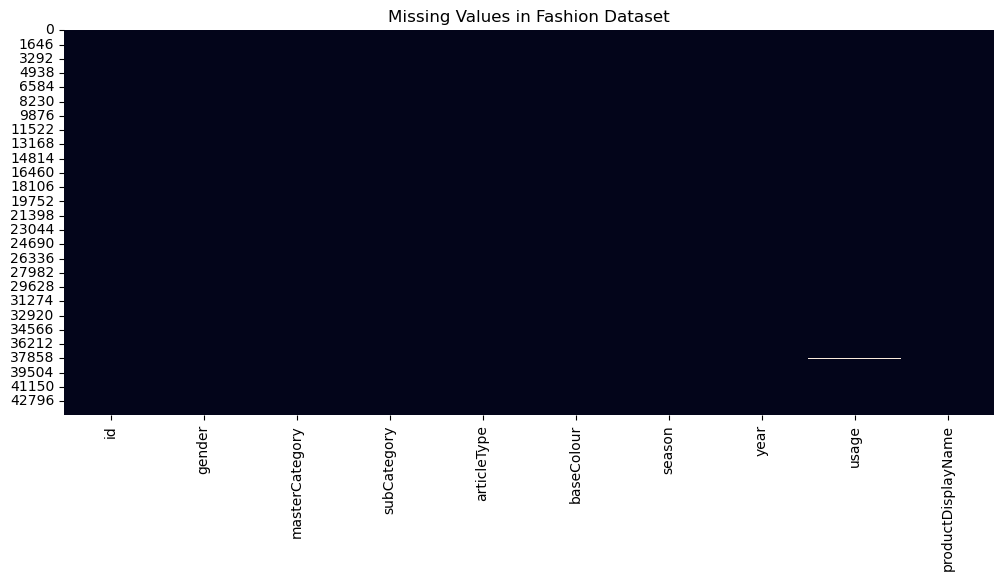

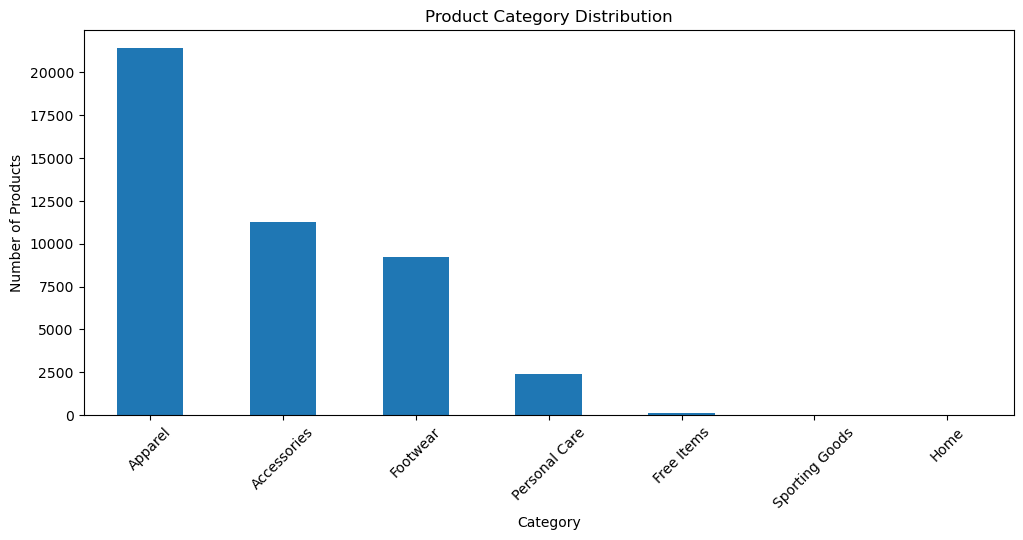

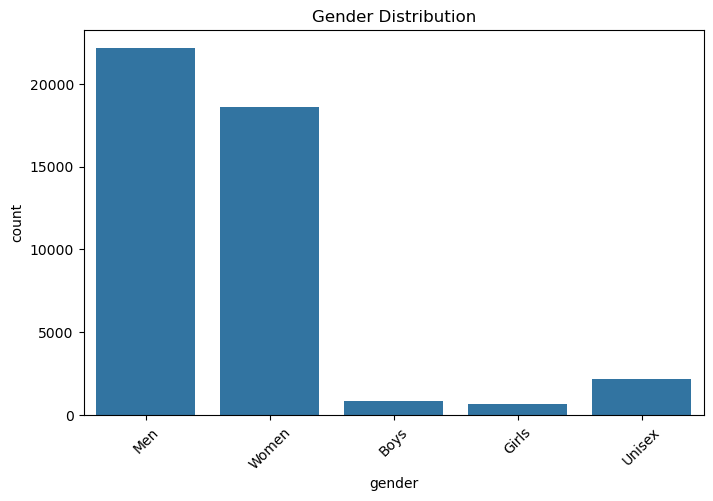

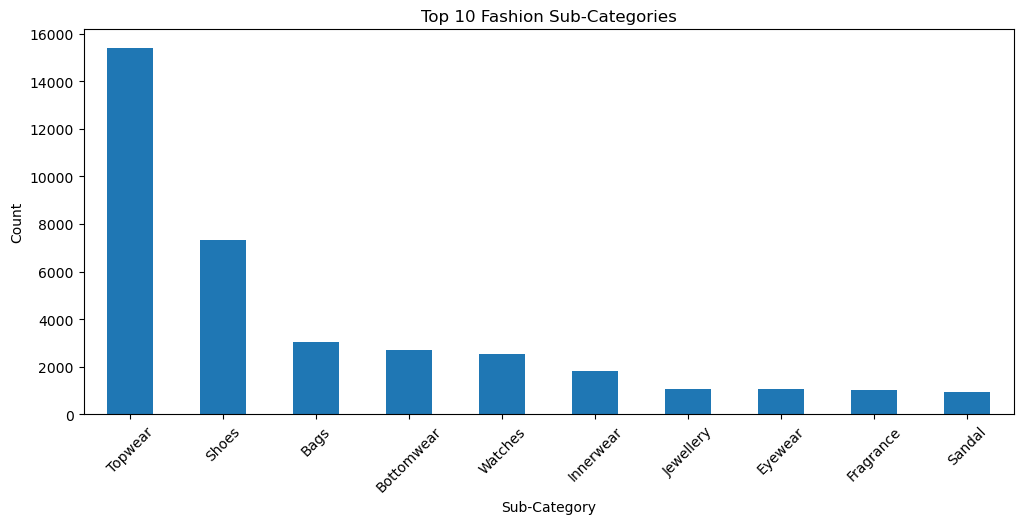

EDA Completed Successfully!


In [18]:
# 1. Dataset overview
print("Dataset Shape:", df.shape)

# 2. Display column names
print("\nColumns:")
print(df.columns.tolist())

# 3. Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all"))

# 4. Missing values visualization
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values in Fashion Dataset")
plt.show()

# 5. Check product category distribution
if "masterCategory" in df.columns:
    plt.figure(figsize=(12, 5))
    df["masterCategory"].value_counts().plot(kind="bar")
    plt.title("Product Category Distribution")
    plt.xlabel("Category")
    plt.ylabel("Number of Products")
    plt.xticks(rotation=45)
    plt.show()

# 6. Check gender distribution
if "gender" in df.columns:
    plt.figure(figsize=(8, 5))
    sns.countplot(data=df, x="gender")
    plt.title("Gender Distribution")
    plt.xticks(rotation=45)
    plt.show()

# 7. Check sub-category distribution
if "subCategory" in df.columns:
    plt.figure(figsize=(12, 5))
    df["subCategory"].value_counts().head(10).plot(kind="bar")
    plt.title("Top 10 Fashion Sub-Categories")
    plt.xlabel("Sub-Category")
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.show()

print("EDA Completed Successfully!")

**Feature Engineering**

In [19]:
# 1. Check available columns
print("Available Columns:")
print(df.columns.tolist())


# 2. Select useful fashion features
features = [
    "gender",
    "masterCategory",
    "subCategory",
    "articleType",
    "baseColour",
    "season",
    "usage",
    "productDisplayName"
]

# 3. Keep only columns available in dataset
features = [col for col in features if col in df.columns]

# 4. Create a new feature dataset
fashion_features = df[features].copy()

# 5. Fill missing values
fashion_features = fashion_features.fillna("Unknown")

# 6. Convert text into lowercase
for col in fashion_features.select_dtypes(include="object").columns:
    fashion_features[col] = fashion_features[col].str.lower()

# 7. Combine features into one column
fashion_features["combined_features"] = (
    fashion_features.astype(str).agg(" ".join, axis=1)
)

# 8. Display prepared features
display(fashion_features.head())

print("Feature Engineering Completed Successfully!")

Available Columns:
['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName']


,gender,masterCategory,subCategory,articleType,baseColour,season,usage,productDisplayName,combined_features
0,men,apparel,topwear,shirts,navy blue,fall,casual,turtle check men navy blue shirt,men apparel topwear shirts navy blue fall casu...
1,men,apparel,bottomwear,jeans,blue,summer,casual,peter england men party blue jeans,men apparel bottomwear jeans blue summer casua...
2,women,accessories,watches,watches,silver,winter,casual,titan women silver watch,women accessories watches watches silver winte...
3,men,apparel,bottomwear,track pants,black,fall,casual,manchester united men solid black track pants,men apparel bottomwear track pants black fall ...
4,men,apparel,topwear,tshirts,grey,summer,casual,puma men grey t-shirt,men apparel topwear tshirts grey summer casual...


Feature Engineering Completed Successfully!


**Content-Based Filtering**

In [20]:
# 1. Import required library
from sklearn.feature_extraction.text import TfidfVectorizer

# 2. Convert product features into numerical values
tfidf = TfidfVectorizer(stop_words="english")

feature_matrix = tfidf.fit_transform(
    fashion_features["combined_features"]
)

# 3. Check feature matrix
print("Feature Matrix Shape:", feature_matrix.shape)

# 4. Display sample feature names
print("\nSample Features:")
print(tfidf.get_feature_names_out()[:20])

print("\nContent-Based Filtering Completed Successfully!")

Feature Matrix Shape: (44424, 8593)

Sample Features:
['00' '0002' '001' '002' '003' '004' '005' '005g' '006' '007' '008' '009'
 '01' '010' '0105' '011' '012' '013' '014' '015']

Content-Based Filtering Completed Successfully!


**Cosine Similarity**

In [21]:
# 1. Import Cosine Similarity
from sklearn.metrics.pairwise import cosine_similarity

# 2. Calculate similarity between products
cosine_sim = cosine_similarity(feature_matrix)

# 3. Check similarity matrix shape
print("Similarity Matrix Shape:", cosine_sim.shape)

# 4. Display similarity scores for first 5 products
print("\nSimilarity Scores:")
print(cosine_sim[:5, :5])

print("\nCosine Similarity Completed Successfully!")

Similarity Matrix Shape: (44424, 44424)

Similarity Scores:
[[1.         0.18823445 0.0071399  0.07223298 0.18460511]
 [0.18823445 1.         0.00600747 0.08581263 0.10578639]
 [0.0071399  0.00600747 1.         0.00508348 0.01004711]
 [0.07223298 0.08581263 0.00508348 1.         0.0755057 ]
 [0.18460511 0.10578639 0.01004711 0.0755057  1.        ]]

Cosine Similarity Completed Successfully!


**KNN**

In [ ]:
# 1. Import KNN
from sklearn.neighbors import NearestNeighbors

# 2. Create KNN model
knn_model = NearestNeighbors(
    n_neighbors=6,
    metric="cosine",
    algorithm="brute"
)

# 3. Train the model
knn_model.fit(feature_matrix)

# 4. Test with first product
distances, indices = knn_model.kneighbors(
    feature_matrix[0]
)

# 5. Display recommended products
print("Recommended Fashion Products:\n")

for i in range(1, len(indices[0])):
    product_index = indices[0][i]
    print(df.iloc[product_index]["productDisplayName"]
          if "productDisplayName" in df.columns
          else df.index[product_index])

print("\nKNN Recommendation Model Created Successfully!")

**Test Fashion Recommendations**

In [ ]:
# Function to recommend fashion products
def recommend_products(product_index, number_of_recommendations=5):

    distances, indices = knn_model.kneighbors(
        feature_matrix[product_index],
        n_neighbors=number_of_recommendations + 1
    )

    print("Selected Product:")
    print(df.iloc[product_index]["productDisplayName"]
          if "productDisplayName" in df.columns
          else df.index[product_index])

    print("\nRecommended Products:\n")

    for i in range(1, len(indices[0])):

        recommended_index = indices[0][i]

        product_name = (
            df.iloc[recommended_index]["productDisplayName"]
            if "productDisplayName" in df.columns
            else f"Product {recommended_index}"
        )

        similarity_score = 1 - distances[0][i]

        print(f"{i}. {product_name}")
        print(f"   Similarity: {similarity_score:.2f}")


# Test recommendation system
recommend_products(0, 5)

In [24]:
# Save cleaned dataset
df.to_csv(
    r"C:\Users\swapn\OneDrive\Desktop\fashan\fashion_cleaned.csv",
    index=False
)

print("Fashion cleaned dataset saved successfully!")

Fashion cleaned dataset saved successfully!
